# 01 · Keşifsel Veri Analizi (BIST 100)

Bu notebook **sadece önbellekteki veriyi okur** (internete bağlanmaz). Önce veriyi güncelleyin:
`python -m src.data.guncelle`

Sorular:
1. Veri ne kadar eksiksiz? Hangi hisselerin geçmişi kısa?
2. Ham ve düzeltilmiş fiyat neden farklı, düzeltme doğru mu?
3. TL bazında ve USD bazında BIST getirisi ne kadar farklı?
4. Getiriler normal dağılıyor mu?
5. Temettü verimi en yüksek hisseler hangileri?
6. Enflasyon ve faiz nasıl seyretti?

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config
from src.data import cache, dividends, quality
from src.data.fetch import elle_duzeltmeleri_uygula, elle_duzeltmeler, tatil_satirlarini_at

pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.3f}".format)

# Grafik stili: açık zemin, sade eksenler, sabit renk sırası
MAVI, TURUNCU = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#ebeae6", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.axisbelow": True,
})

def oku(sembol, duzelt=True):
    # Önbellekten okur; tatil satırlarını atar ve referans/duzeltmeler.csv'yi uygular
    df = cache.oku(sembol)
    if df is None:
        return None
    df = tatil_satirlarini_at(df)
    return elle_duzeltmeleri_uygula(df, elle_duzeltmeler(sembol)) if duzelt else df

hisseler = config.hisse_evreni("bist100")
veri = {h: df for h in hisseler if (df := oku(config.yf_sembol(h))) is not None}
endeks, kur = oku(config.ENDEKS), oku(config.USDTRY)
makro = cache.oku("evds", "makro")
print(f"Önbellekte {len(veri)}/{len(hisseler)} hisse | XU100: {endeks is not None} | USD/TRY: {kur is not None} | EVDS: {makro is not None}")

Önbellekte 100/100 hisse | XU100: False | USD/TRY: True | EVDS: True


## 1. Kapsam ve veri kalitesi
2015'ten sonra halka arz olan hisselerin geçmişi kısadır. Bu, ML'de örnek sayısını ve walk-forward pencerelerini etkiler.

In [2]:
takvim = endeks.index if endeks is not None else None
kalite = quality.kalite_tablosu(veri, takvim)
kalite["yil"] = (pd.to_datetime(kalite["son_tarih"]) - pd.to_datetime(kalite["ilk_tarih"])).dt.days / 365.25
print("Geçmişi 5 yıldan kısa olan hisseler:")
display(kalite[kalite["yil"] < 5][["ilk_tarih", "satir", "yil"]].sort_values("yil"))
print("\nÖzet:")
display(kalite[["satir", "nan", "yinelenen_tarih", "sifir_hacim", "ohlc_tutarsiz", "limit_asimi", "bolunme", "temettu"]].describe().loc[["mean", "min", "max"]])

Geçmişi 5 yıldan kısa olan hisseler:


,ilk_tarih,satir,yil
PAHOL,2025-11-21,247,1.008
GLRMK,2025-01-17,464,1.851
TCKRC,2024-08-26,565,2.245
ALTNY,2024-05-16,633,2.524
RGYAS,2024-05-02,643,2.563
ENTRA,2024-04-04,658,2.639
BINHO,2024-03-21,667,2.678
OBAMS,2024-03-01,681,2.732
LMKDC,2024-02-22,687,2.754
TABGD,2023-10-26,771,3.080



Özet:


,satir,nan,yinelenen_tarih,sifir_hacim,ohlc_tutarsiz,limit_asimi,bolunme,temettu
mean,"2,496.160",0.000,0.000,0.000,0.000,6.490,1.080,6.920
min,247.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
max,"2,982.000",0.000,0.000,0.000,0.000,45.000,9.000,28.000


### ±%10 limitini aşan günler
BIST'te günlük fiyat limiti ±%10. Aşan günlerin bir kısmı gerçek olaydır (darbe girişimi 2016-07-18, deprem sonrası açılış 2023-02-15, COVID 2020-03),
bir kısmı ise Yahoo'nun düzeltmediği **bedelli sermaye artırımlarıdır** (sahte düşüş). Hangi tarihlerin birden çok hissede görüldüğüne bakalım:

In [3]:
tarihler = pd.Series([t for r in kalite["limit_asimi_tarihleri"] for t in r]).value_counts()
print("En çok hissede aynı anda görülen limit aşımları (piyasa geneli olay):")
display(tarihler.head(8).rename("hisse_sayisi").to_frame())
print(f"Tek hissede görülen limit aşımı: {(tarihler == 1).sum()} gün (şirkete özel olay ya da veri sorunu)")

En çok hissede aynı anda görülen limit aşımları (piyasa geneli olay):


,hisse_sayisi
2023-02-15,81
2020-03-12,37
2016-07-18,16
2015-06-08,14
2020-03-09,11
2020-03-16,10
2018-08-13,9
2015-11-02,8


Tek hissede görülen limit aşımı: 313 gün (şirkete özel olay ya da veri sorunu)


## 2. Ham ve düzeltilmiş fiyat
FROTO 2025-05-07'de 1'e 10 bedelsiz yaptı. Ham fiyat o gün ~%90 "düşer", ama yatırımcının serveti değişmez: hisse sayısı 10 katına çıkar.
Getiri hesabında ham fiyat kullanılırsa sahte bir -%90 oluşur. Bu yüzden iki seriyi ayrı tutuyoruz.

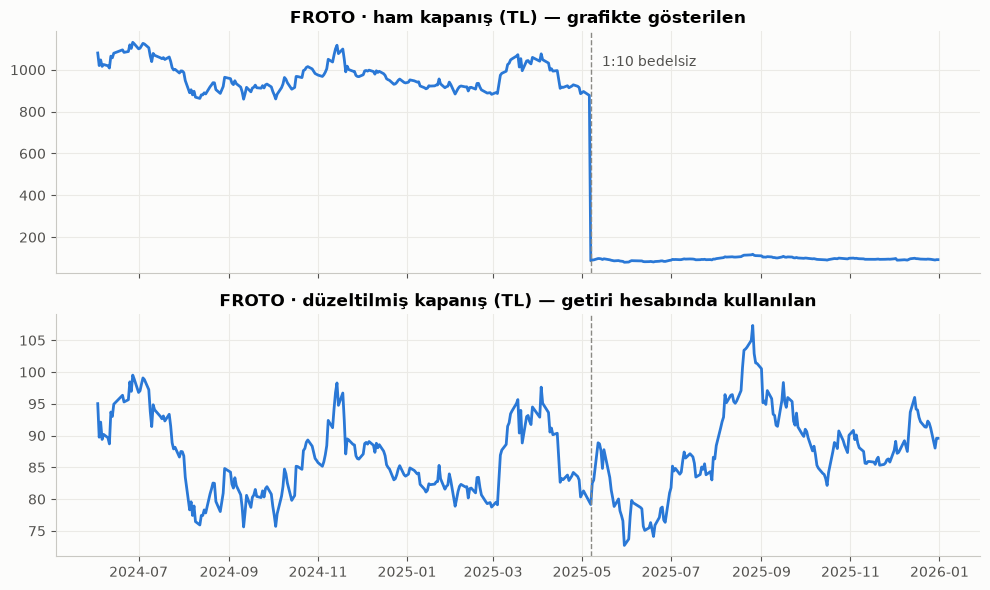

Bölünme hesabının doğrulanması (sapma ≈ 1 olmalı):
108 bölünme, sapma min=1.000 max=1.000


In [4]:
froto = veri["FROTO"].loc["2024-06":"2025-12"]
fig, eks = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
eks[0].plot(froto.index, froto["kapanis"], color=MAVI)
eks[0].set_title("FROTO · ham kapanış (TL) — grafikte gösterilen")
eks[1].plot(froto.index, froto["duz_kapanis"], color=MAVI)
eks[1].set_title("FROTO · düzeltilmiş kapanış (TL) — getiri hesabında kullanılan")
for e in eks:
    e.axvline(pd.Timestamp("2025-05-07"), color="#8a8984", linestyle="--", linewidth=1)
eks[0].annotate("1:10 bedelsiz", (pd.Timestamp("2025-05-07"), froto["kapanis"].max() * 0.9),
                xytext=(8, 0), textcoords="offset points", color="#52514e")
plt.tight_layout(); plt.show()

print("Bölünme hesabının doğrulanması (sapma ≈ 1 olmalı):")
kontrol = pd.concat({h: quality.bolunme_kontrolu(df) for h, df in veri.items()})
print(f"{len(kontrol)} bölünme, sapma min={kontrol['sapma'].min():.3f} max={kontrol['sapma'].max():.3f}")

### Yahoo'nun kaçırdığı sermaye artırımları
Bazı bedelsiz/bedelli artırımlar Yahoo'da hiç kayıtlı değil ya da yanlış oranla kayıtlı. Sonuç: düzeltilmiş seride gerçekte yaşanmamış
"-%91 çöküşler". Bunları %35'ten büyük günlük hareketlerle tespit edip `referans/duzeltmeler.csv` dosyasına yazdık.
Oranlar şimdilik **fiyattan tahmin**; KAP duyurularından doğrulanacak.

Düzeltme öncesi şüpheli gün: 10 (7 hisse) | sonrası: 0


,kod,tarih,oran,aciklama,kaynak
0,AYGAZ,2022-09-01,0.580,fiyattan tahmin (getiri %72.5),KAP ile dogrulanacak
1,CCOLA,2024-08-01,10.808,fiyattan tahmin (getiri %-90.7),KAP ile dogrulanacak
2,CVKMD,2026-08-03,2.623,fiyattan tahmin (getiri %-61.9),KAP ile dogrulanacak
3,EUREN,2024-12-02,2.743,fiyattan tahmin (getiri %-63.5),KAP ile dogrulanacak
4,FENER,2024-12-09,2.469,fiyattan tahmin (getiri %-59.5),KAP ile dogrulanacak
5,FENER,2025-06-23,4.679,fiyattan tahmin (getiri %-78.6),KAP ile dogrulanacak
6,FENER,2025-12-29,2.754,fiyattan tahmin (getiri %-63.7),KAP ile dogrulanacak
7,HEKTS,2021-04-30,1.403,fiyattan tahmin (getiri %44.1),KAP ile dogrulanacak
8,HEKTS,2024-09-09,2.845,fiyattan tahmin (getiri %-64.8),KAP ile dogrulanacak
9,TUKAS,2025-02-03,3.071,fiyattan tahmin (getiri %-67.4),KAP ile dogrulanacak


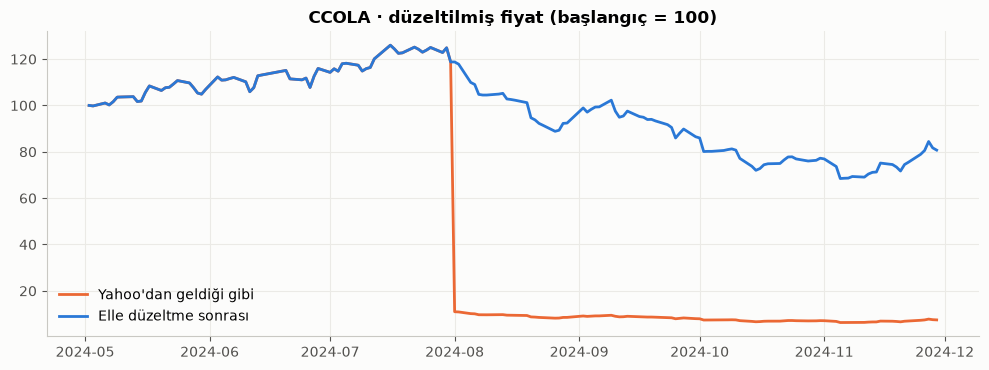

In [5]:
ham_veri = {h: oku(config.yf_sembol(h), duzelt=False) for h in veri}
once = pd.concat({h: quality.supheli_sicramalar(df) for h, df in ham_veri.items()})
sonra = pd.concat({h: quality.supheli_sicramalar(df) for h, df in veri.items()}) if any(
    len(quality.supheli_sicramalar(df)) for df in veri.values()) else pd.DataFrame()
print(f"Düzeltme öncesi şüpheli gün: {len(once)} ({once.index.get_level_values(0).nunique()} hisse) | sonrası: {len(sonra)}")
display(pd.read_csv(config.REFERANS_DIZINI / "duzeltmeler.csv", comment="#"))

ccola_once, ccola_sonra = ham_veri["CCOLA"].loc["2024-05":"2024-11"], veri["CCOLA"].loc["2024-05":"2024-11"]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(ccola_once.index, ccola_once["duz_kapanis"] / ccola_once["duz_kapanis"].iloc[0] * 100, color=TURUNCU, label="Yahoo'dan geldiği gibi")
ax.plot(ccola_sonra.index, ccola_sonra["duz_kapanis"] / ccola_sonra["duz_kapanis"].iloc[0] * 100, color=MAVI, label="Elle düzeltme sonrası")
ax.set_title("CCOLA · düzeltilmiş fiyat (başlangıç = 100)"); ax.legend(frameon=False, loc="lower left")
plt.tight_layout(); plt.show()

## 3. TL ve USD bazında getiri
Yüksek enflasyonlu bir ülkede TL getirisi yanıltıcı olabilir. Aynı endeksi USD'ye çevirip 100'den başlatarak karşılaştırıyoruz (tek eksen, ortak baz).

In [6]:
if endeks is None or kur is None:
    print("XU100 ya da USD/TRY önbellekte yok; bu bölüm atlandı. `python -m src.data.guncelle` ile tekrar deneyin.")
else:
    ortak = endeks.index.intersection(kur.index)
    tl = endeks.loc[ortak, "duz_kapanis"]
    usd = tl / kur.loc[ortak, "kapanis"]
    tl_e, usd_e = tl / tl.iloc[0] * 100, usd / usd.iloc[0] * 100
    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.plot(tl_e.index, tl_e, color=MAVI, label="XU100 (TL)")
    ax.plot(usd_e.index, usd_e, color=TURUNCU, label="XU100 (USD)")
    ax.set_yscale("log"); ax.set_ylabel("Endeks (başlangıç = 100, log ölçek)")
    ax.set_title("BIST 100: TL ve USD bazında")
    for seri, renk in [(tl_e, MAVI), (usd_e, TURUNCU)]:
        ax.annotate(f"{seri.iloc[-1]:,.0f}", (seri.index[-1], seri.iloc[-1]), xytext=(4, 0),
                    textcoords="offset points", color="#0b0b0b", va="center")
    ax.legend(frameon=False, loc="upper left")
    plt.tight_layout(); plt.show()
    yil = (ortak[-1] - ortak[0]).days / 365.25
    print(f"Yıllık bileşik getiri ({ortak[0].date()} → {ortak[-1].date()}): "
          f"TL %{((tl.iloc[-1]/tl.iloc[0])**(1/yil)-1)*100:.1f} | USD %{((usd.iloc[-1]/usd.iloc[0])**(1/yil)-1)*100:.1f}")

XU100 ya da USD/TRY önbellekte yok; bu bölüm atlandı. `python -m src.data.guncelle` ile tekrar deneyin.


## 4. Günlük getirilerin dağılımı
Finansal getiriler normal dağılmaz: kuyruklar kalındır (aşırı günler beklenenden sık). Basıklık (kurtosis) 0'dan büyükse kuyruk kalındır.

In [7]:
getiri = pd.DataFrame({h: df["duz_kapanis"].pct_change() for h, df in veri.items()})
ozet = pd.DataFrame({
    "yillik_volatilite": getiri.std() * np.sqrt(252),
    "basiklik": getiri.kurt(),
    "carpiklik": getiri.skew(),
    "pozitif_gun_orani": (getiri > 0).sum() / getiri.notna().sum(),
}).sort_values("yillik_volatilite")
display(ozet.describe().loc[["mean", "min", "50%", "max"]])
print("\n'Pozitif gün oranı' ML için önemli: 'hep yükselir' tahmini bu oranda doğru çıkar → baseline.")

,yillik_volatilite,basiklik,carpiklik,pozitif_gun_orani
mean,0.445,3.728,0.401,0.483
min,0.304,0.443,-0.198,0.398
50%,0.431,3.480,0.343,0.487
max,0.641,9.315,1.083,0.552



'Pozitif gün oranı' ML için önemli: 'hep yükselir' tahmini bu oranda doğru çıkar → baseline.


## 5. Temettü
Son 12 ay verimi = son 12 ayda ödenen temettüler (bugünkü hisse sayısı bazında) / son fiyat. Tutarlar brüttür.

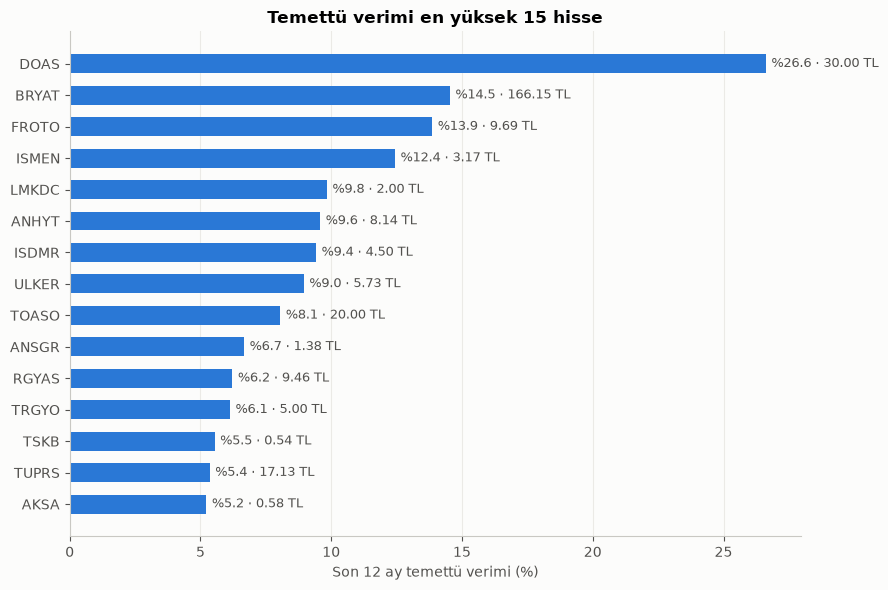

Filtre örneği: verim ≥ %5 ve en az 5 yıl kesintisiz


,son_fiyat,son_temettu_tarihi,son_temettu_tl,son12ay_tl,son12ay_verim,son12ay_odeme_sayisi,kesintisiz_yil
kod,,,,,,,
DOAS,112.700,2026-08-13,15.000,30.000,0.266,2,6
BRYAT,"1,143.000",2026-04-08,166.146,166.146,0.145,1,12
FROTO,69.900,2026-03-16,3.640,9.690,0.139,2,12
ISMEN,25.460,2026-04-01,3.167,3.167,0.124,1,12
ANHYT,85.000,2026-03-26,8.140,8.140,0.096,1,12
TOASO,248.400,2026-03-23,20.000,20.000,0.081,1,12
AKSA,11.100,2026-04-03,0.580,0.580,0.052,1,12
TURSG,2.890,2026-08-27,0.150,0.150,0.052,1,6
AYGAZ,241.800,2026-03-16,12.550,12.550,0.052,1,12


In [8]:
ozet_t = dividends.temettu_ozeti(veri).sort_values("son12ay_verim", ascending=False)
ilk15 = ozet_t.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(ilk15.index, ilk15["son12ay_verim"] * 100, color=MAVI, height=0.6)
for i, (v, tl) in enumerate(zip(ilk15["son12ay_verim"] * 100, ilk15["son12ay_tl"])):
    ax.annotate(f"%{v:.1f} · {tl:.2f} TL", (v, i), xytext=(4, 0), textcoords="offset points",
                va="center", color="#52514e", fontsize=9)
ax.set_xlabel("Son 12 ay temettü verimi (%)"); ax.grid(axis="y", visible=False)
ax.set_title("Temettü verimi en yüksek 15 hisse")
plt.tight_layout(); plt.show()
print("Filtre örneği: verim ≥ %5 ve en az 5 yıl kesintisiz")
display(dividends.filtrele(ozet_t, min_verim=0.05, min_kesintisiz_yil=5))

## 6. Enflasyon ve politika faizi
İkisi de yüzde cinsinden, aynı eksende gösterilebilir. **Dikkat:** TÜFE ay bittikten sonra açıklanır; modelde `tufe_yayin_tarihi` kullanılmalı.

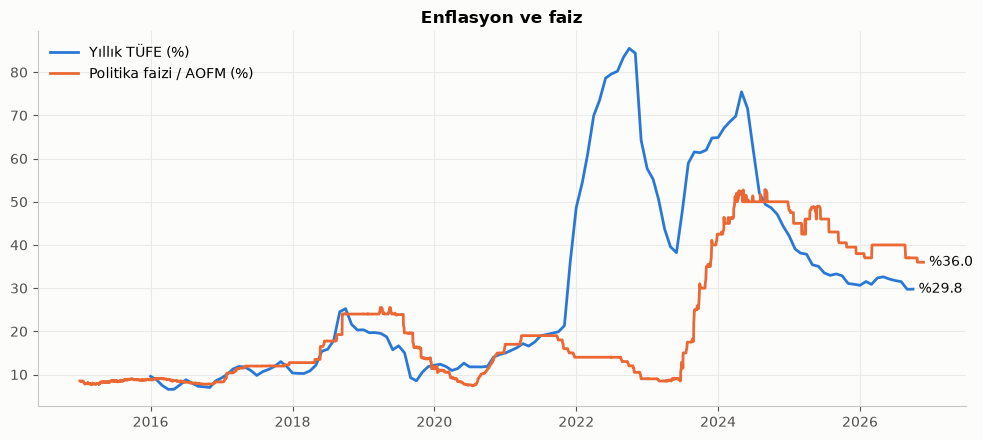

Son ay reel faiz (faiz − yıllık enflasyon): 7.0 puan


In [9]:
if makro is None:
    print("EVDS verisi yok (.env içinde EVDS_API_KEY tanımlayın).")
else:
    tufe = makro["tufe"].dropna()
    enflasyon = (tufe / tufe.shift(12) - 1).dropna() * 100
    faiz = makro["politika_faizi"].dropna()
    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.plot(enflasyon.index, enflasyon, color=MAVI, label="Yıllık TÜFE (%)")
    ax.plot(faiz.index, faiz, color=TURUNCU, label="Politika faizi / AOFM (%)")
    for seri, renk in [(enflasyon, MAVI), (faiz, TURUNCU)]:
        ax.annotate(f"%{seri.iloc[-1]:.1f}", (seri.index[-1], seri.iloc[-1]), xytext=(4, 0),
                    textcoords="offset points", color="#0b0b0b", va="center")
    ax.set_title("Enflasyon ve faiz"); ax.legend(frameon=False, loc="upper left")
    plt.tight_layout(); plt.show()
    reel = faiz.resample("MS").mean().reindex(enflasyon.index) - enflasyon
    print(f"Son ay reel faiz (faiz − yıllık enflasyon): {reel.dropna().iloc[-1]:.1f} puan")

## Aşama 2 için çıkarımlar
- Getiri hesapları **düzeltilmiş** fiyatla yapılmalı; ham fiyat sadece gösterim içindir.
- **Baseline:** "hep yükselir" tahmininin doğruluğu pozitif gün oranına eşittir; model bunu geçmeli.
- Yahoo'nun kaçırdığı artırımlar elle düzeltildi (oranlar KAP'tan doğrulanmalı); yeni veride `supheli_sicrama` kontrolü takip edilmeli.
- Kalın kuyruklar (deprem sonrası açılış, COVID) gerçek olaylardır; silinmez ama modelde dikkate alınır.
- Kısa geçmişli hisseler walk-forward'da az pencere üretir; minimum geçmiş şartı konmalı.
- Makro veriler yayın tarihine göre gecikmeli kullanılmalı (look-ahead bias).
- TL getirisinin önemli kısmı enflasyondan geliyor: USD ve reel getiri ayrı raporlanmalı.